Huimin Guo

guo.hu@northeastern.edu

NEUID: 002828299

## Data Processing

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import torch
from torch.utils.data import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.utils import shuffle

In [2]:
# read data
df = pd.read_csv("RedNoteComment.tsv", sep='\t')

display(df.head())
# lable 1: Positive, lable 0: Negative

,lable,test1_a
0,1,好看就少人追，都知道追也追不上
1,1,读大学时候有一次坐公交，我一开始用的公交卡，但貌似遇到雾霭天，公交卡不收费，我还傻愣愣拿出手...
2,1,我选择直接吃药店一两块钱的版维
3,0,要看在什么场所。
4,1,很难让人不怀疑他收钱了


In [3]:
# check data type
df.dtypes

lable       int64
test1_a    object
dtype: object

In [5]:
# check missing data
df.isna().sum()

lable      0
test1_a    0
dtype: int64

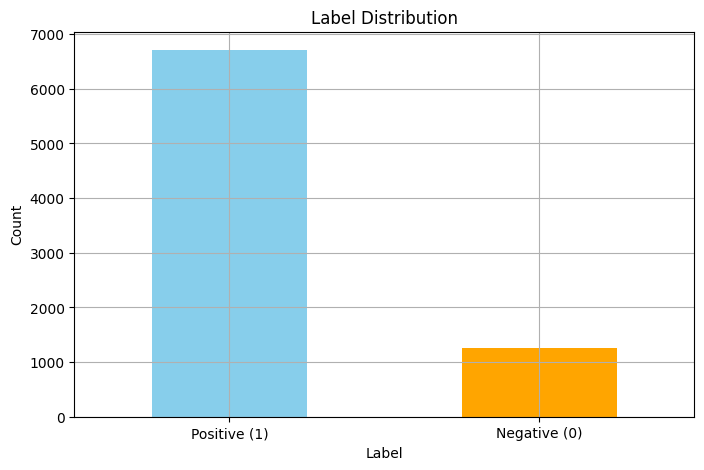

In [7]:
# Label distribution plot
plt.figure(figsize=(8, 5))
df['lable'].value_counts().plot(kind='bar', color=['skyblue', 'orange'])
plt.title('Label Distribution')
plt.xlabel('Label')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Positive (1)', 'Negative (0)'], rotation = 0)
plt.grid(True)
plt.show()

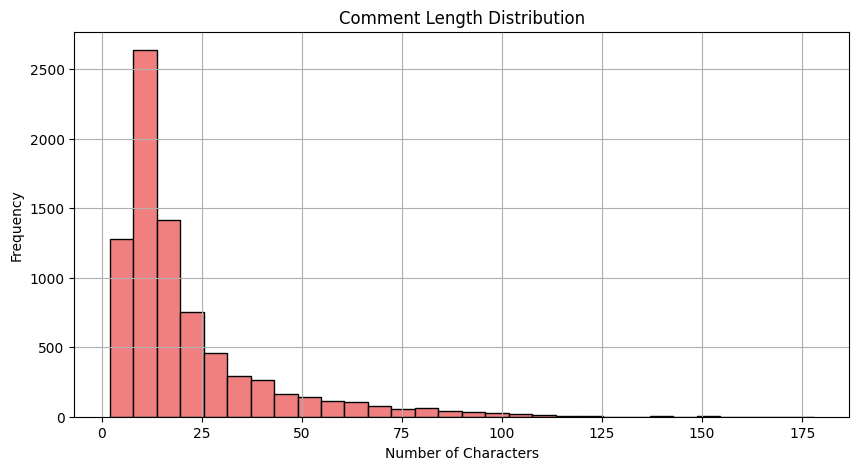

In [8]:
# Comment length distribution plot
comment_lengths = df['test1_a'].astype(str).apply(len)

plt.figure(figsize=(10, 5))
plt.hist(comment_lengths, bins=30, color='lightcoral', edgecolor='black')
plt.title('Comment Length Distribution')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [4]:
# shuffle the data to prevent data regularity
df = shuffle(df, random_state=42).reset_index(drop=True)

# display the first few rows of the shuffled data
df.head()

,lable,test1_a
0,0,这个不搭界的
1,1,！！！！第一次喝太甜了，就再也没喝过了！这个出去吃饭点一下子还可以！这比奶茶香
2,1,笑吐了哈哈哈哈
3,1,如有雷同汗流浃背了
4,1,快来看，我要被吓死了


## Build Bert Model and Evaluate Performance

In [5]:
# spilt data for model
texts = df['test1_a'].tolist()
labels = df['lable'].tolist()

train_texts, val_texts, train_labels, val_labels = train_test_split(texts, labels, test_size=0.2, random_state=42)

In [6]:
tokenizer = BertTokenizer.from_pretrained("bert-base-chinese")

# tokenize data
def tokenize_data(texts, labels, tokenizer, max_length=128):
    encodings = tokenizer(texts, truncation=True, padding=True, max_length=max_length)
    return encodings, labels

# tokenize training data and validation data
train_encodings, train_labels = tokenize_data(train_texts, train_labels, tokenizer)
val_encodings, val_labels = tokenize_data(val_texts, val_labels, tokenizer)

In [7]:
# define a custom dataset class for sentiment analysis
class SentimentDataset(Dataset):
    # initialization method that receives tokenized text data and labels
    def __init__(self, encodings, labels):
        self.encodings = encodings  # store tokenized text encodings
        self.labels = labels        # store corresponding labels

    # return the length of the dataset
    def __len__(self):
        return len(self.labels)  # dataset length is the number of labels

    # retrieve a specific sample from the dataset using an index
    def __getitem__(self, idx):
        # convert each encoding feature (e.g., 'input_ids', 'attention_mask') to PyTorch tensors
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        # convert the label to a tensor and add it to the item dictionary
        item['labels'] = torch.tensor(self.labels[idx])
        return item  # return a dictionary containing the features and label for one sample

# create a training dataset object using the custom dataset class
train_dataset = SentimentDataset(train_encodings, train_labels)

# create a validation dataset object using the custom dataset class
val_dataset = SentimentDataset(val_encodings, val_labels)

### epoch = 3

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-chinese and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/homebrew/lib/python3.11/site-packages/transformers/training_args.py:1559: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


  0%|          | 0/1197 [00:00<?, ?it/s]

{'loss': 0.37, 'grad_norm': 2.7942957878112793, 'learning_rate': 4.958228905597327e-05, 'epoch': 0.03}
{'loss': 0.4352, 'grad_norm': 2.074368476867676, 'learning_rate': 4.916457811194654e-05, 'epoch': 0.05}
{'loss': 0.4136, 'grad_norm': 2.1780505180358887, 'learning_rate': 4.8746867167919805e-05, 'epoch': 0.08}
{'loss': 0.448, 'grad_norm': 5.110764503479004, 'learning_rate': 4.8329156223893066e-05, 'epoch': 0.1}
{'loss': 0.4564, 'grad_norm': 2.17114520072937, 'learning_rate': 4.791144527986633e-05, 'epoch': 0.13}
{'loss': 0.4248, 'grad_norm': 5.678269386291504, 'learning_rate': 4.74937343358396e-05, 'epoch': 0.15}
{'loss': 0.48, 'grad_norm': 2.70444917678833, 'learning_rate': 4.707602339181287e-05, 'epoch': 0.18}
{'loss': 0.5484, 'grad_norm': 4.064943313598633, 'learning_rate': 4.6658312447786136e-05, 'epoch': 0.2}
{'loss': 0.4747, 'grad_norm': 4.526346206665039, 'learning_rate': 4.62406015037594e-05, 'epoch': 0.23}
{'loss': 0.4571, 'grad_norm': 4.012066841125488, 'learning_rate': 4.58

  0%|          | 0/100 [00:00<?, ?it/s]

{'eval_loss': 0.40689852833747864, 'eval_runtime': 8.7847, 'eval_samples_per_second': 181.451, 'eval_steps_per_second': 11.383, 'epoch': 1.0}
{'loss': 0.4575, 'grad_norm': 4.896030426025391, 'learning_rate': 3.329156223893066e-05, 'epoch': 1.0}
{'loss': 0.3312, 'grad_norm': 10.588542938232422, 'learning_rate': 3.287385129490393e-05, 'epoch': 1.03}
{'loss': 0.3686, 'grad_norm': 7.0810770988464355, 'learning_rate': 3.24561403508772e-05, 'epoch': 1.05}
{'loss': 0.2973, 'grad_norm': 6.16848087310791, 'learning_rate': 3.2038429406850464e-05, 'epoch': 1.08}
{'loss': 0.3852, 'grad_norm': 4.146612167358398, 'learning_rate': 3.162071846282373e-05, 'epoch': 1.1}
{'loss': 0.4129, 'grad_norm': 3.827409505844116, 'learning_rate': 3.120300751879699e-05, 'epoch': 1.13}
{'loss': 0.4177, 'grad_norm': 6.791852951049805, 'learning_rate': 3.078529657477026e-05, 'epoch': 1.15}
{'loss': 0.3191, 'grad_norm': 3.0576493740081787, 'learning_rate': 3.0367585630743527e-05, 'epoch': 1.18}
{'loss': 0.2518, 'grad_no

  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Evaluation Results: {'eval_loss': 0.40689852833747864, 'eval_runtime': 8.1499, 'eval_samples_per_second': 195.585, 'eval_steps_per_second': 12.27, 'epoch': 3.0}


  0%|          | 0/100 [00:00<?, ?it/s]

accuracy: 0.8432
precision: 0.8440
recall: 0.9985
F1: 0.9148


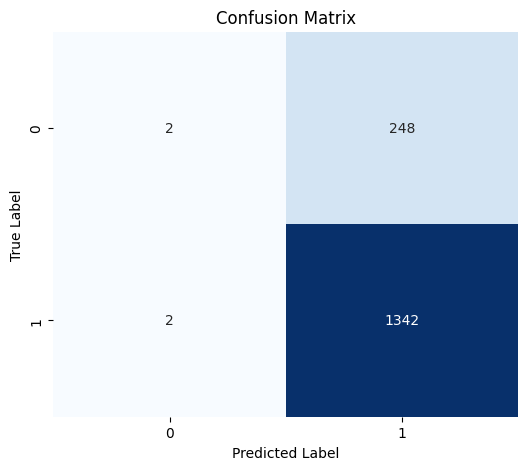

In [9]:
# load Bert model and change epoch to 3
model = BertForSequenceClassification.from_pretrained("bert-base-chinese", num_labels=2)

training_args = TrainingArguments(
    output_dir='./results',          # directory to save output
    evaluation_strategy="epoch",     # evaluate after each epoch
    save_strategy="epoch",           # save model after each epoch 
    per_device_train_batch_size=16,  # batch size per device for training
    per_device_eval_batch_size=16,   # batch size per device for evaluation
    num_train_epochs=3,              # number of training epochs
    logging_dir='./logs',            # directory to save logs
    logging_steps=10,                # frequency of logging steps
    load_best_model_at_end=True      # load the best model at the end of training
)

# use the Trainer API for model training and validation
trainer = Trainer(
    model=model,                         # model to be trained
    args=training_args,                  # training arguments
    train_dataset=train_dataset,         # training dataset
    eval_dataset=val_dataset             # validation dataset
)

# start training
trainer.train()

# evaluate model
results = trainer.evaluate()
print(f"Evaluation Results: {results}")

# compare real lables and predicted one
true_labels = val_labels  # real labels
predictions = trainer.predict(val_dataset).predictions.argmax(-1)

# compute model accuracy, precision, recall, f1
accuracy = accuracy_score(true_labels, predictions)
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predictions, average='binary')

print(f"accuracy: {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# visualize matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Metrics and Confusion Matrix Analysis (Epoch = 3)

Accuracy: 84.32%
The model's overall accuracy is relatively high, reflecting good performance on this binary classification task. However, it may still be affected by the imbalance in the dataset.

Precision: 84.40%
Among the predicted positive samples, 84.40% are correct. This shows the model's ability to avoid false positives to a reasonable extent.

Recall: 99.85%
The model correctly identifies 99.85% of the actual positive samples, indicating exceptional sensitivity towards the positive class.

F1 Score: 91.48%
The harmonic mean of precision and recall suggests that the model performs very well in balancing these metrics for the positive class.

Confusion Matrix Analysis

True Positives (TP): 1342
The model successfully identifies a large number of positive samples, highlighting its strength in recognizing positive sentiment.

False Negatives (FN): 2
Very few positive samples are missed, contributing to the high recall.

True Negatives (TN): 2
The model struggles significantly to correctly classify negative samples, indicating a strong bias towards the positive class.

False Positives (FP): 248
Many negative samples are misclassified as positive, showing that the model lacks precision in identifying the negative class.

### epoch = 4

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-chinese and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/homebrew/lib/python3.11/site-packages/transformers/training_args.py:1559: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


  0%|          | 0/1596 [00:00<?, ?it/s]

{'loss': 0.517, 'grad_norm': 2.455857753753662, 'learning_rate': 4.9686716791979956e-05, 'epoch': 0.03}
{'loss': 0.4375, 'grad_norm': 7.281962871551514, 'learning_rate': 4.93734335839599e-05, 'epoch': 0.05}
{'loss': 0.4478, 'grad_norm': 1.541474461555481, 'learning_rate': 4.906015037593985e-05, 'epoch': 0.08}
{'loss': 0.5559, 'grad_norm': 8.030261039733887, 'learning_rate': 4.8746867167919805e-05, 'epoch': 0.1}
{'loss': 0.4072, 'grad_norm': 4.8163743019104, 'learning_rate': 4.843358395989975e-05, 'epoch': 0.13}
{'loss': 0.4272, 'grad_norm': 1.4346747398376465, 'learning_rate': 4.81203007518797e-05, 'epoch': 0.15}
{'loss': 0.4112, 'grad_norm': 2.818002700805664, 'learning_rate': 4.780701754385965e-05, 'epoch': 0.18}
{'loss': 0.4502, 'grad_norm': 3.5832362174987793, 'learning_rate': 4.74937343358396e-05, 'epoch': 0.2}
{'loss': 0.3745, 'grad_norm': 2.709541082382202, 'learning_rate': 4.7180451127819555e-05, 'epoch': 0.23}
{'loss': 0.4242, 'grad_norm': 8.97554874420166, 'learning_rate': 4.

  0%|          | 0/100 [00:00<?, ?it/s]

{'eval_loss': 0.4570961892604828, 'eval_runtime': 9.2501, 'eval_samples_per_second': 172.323, 'eval_steps_per_second': 10.811, 'epoch': 1.0}
{'loss': 0.3192, 'grad_norm': 4.682435035705566, 'learning_rate': 3.7468671679198e-05, 'epoch': 1.0}
{'loss': 0.392, 'grad_norm': 2.7685728073120117, 'learning_rate': 3.715538847117795e-05, 'epoch': 1.03}
{'loss': 0.3675, 'grad_norm': 4.814188003540039, 'learning_rate': 3.6842105263157895e-05, 'epoch': 1.05}
{'loss': 0.3331, 'grad_norm': 3.51206111907959, 'learning_rate': 3.652882205513785e-05, 'epoch': 1.08}
{'loss': 0.4049, 'grad_norm': 2.113443613052368, 'learning_rate': 3.6215538847117796e-05, 'epoch': 1.1}
{'loss': 0.3577, 'grad_norm': 3.358640670776367, 'learning_rate': 3.590225563909775e-05, 'epoch': 1.13}
{'loss': 0.3177, 'grad_norm': 5.307656288146973, 'learning_rate': 3.55889724310777e-05, 'epoch': 1.15}
{'loss': 0.2953, 'grad_norm': 5.553108215332031, 'learning_rate': 3.5275689223057644e-05, 'epoch': 1.18}
{'loss': 0.3918, 'grad_norm': 

  0%|          | 0/100 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Evaluation Results: {'eval_loss': 0.44884639978408813, 'eval_runtime': 8.194, 'eval_samples_per_second': 194.533, 'eval_steps_per_second': 12.204, 'epoch': 4.0}


  0%|          | 0/100 [00:00<?, ?it/s]

accuracy: 0.7942
precision: 0.8533
recall: 0.9076
F1: 0.8796


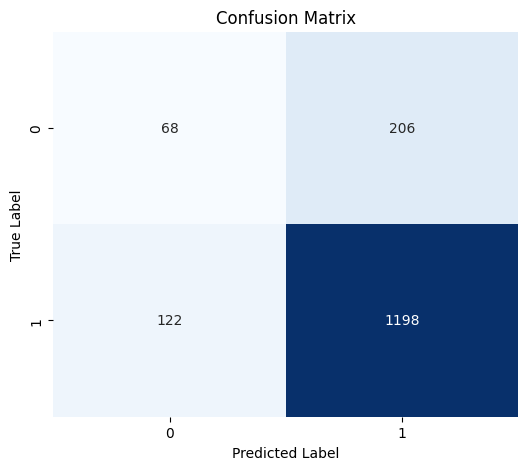

In [ ]:
# load Bert model and change epoch to 4
model = BertForSequenceClassification.from_pretrained("bert-base-chinese", num_labels=2)

training_args = TrainingArguments(
    output_dir='./results',          # directory to save output
    evaluation_strategy="epoch",     # evaluate after each epoch
    save_strategy="epoch",           # save model after each epoch 
    per_device_train_batch_size=16,  # batch size per device for training
    per_device_eval_batch_size=16,   # batch size per device for evaluation
    num_train_epochs=4,              # number of training epochs
    logging_dir='./logs',            # directory to save logs
    logging_steps=10,                # frequency of logging steps
    load_best_model_at_end=True      # load the best model at the end of training
)

# use the Trainer API for model training and validation
trainer = Trainer(
    model=model,                         # model to be trained
    args=training_args,                  # training arguments
    train_dataset=train_dataset,         # training dataset
    eval_dataset=val_dataset             # validation dataset
)

# start training
trainer.train()

# evaluate model
results = trainer.evaluate()
print(f"Evaluation Results: {results}")

# compare real lables and predicted one
true_labels = val_labels  # real labels
predictions = trainer.predict(val_dataset).predictions.argmax(-1)

# compute model accuracy, precision, recall, f1
accuracy = accuracy_score(true_labels, predictions)
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predictions, average='binary')

print(f"accuracy: {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# visualize matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Metrics and Confusion Matrix Analysis(epoch = 4)

Accuracy: 79.42%
The model's overall prediction accuracy is around 80%, but it may be influenced by class imbalance.

Precision: 85.33%
Among the predicted positive samples, 85.33% are correct, indicating good precision for positive class predictions.

Recall: 90.76%
The model correctly identifies 90.76% of the actual positive samples, showing strong coverage of the positive class.

F1 Score: 87.96%
The harmonic mean of precision and recall indicates the model balances these metrics well for the positive class.

Confusion Matrix Analysis

True Positives (TP): 1198 and False Negatives (FN): 122
The model performs well in recognizing positive samples, with few missed cases (high recall).

True Negatives (TN): 68 and False Positives (FP): 206
The model struggles with negative samples, misclassifying many as positive (low recall for the negative class).

### epoch = 5

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-chinese and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/homebrew/lib/python3.11/site-packages/transformers/training_args.py:1559: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


  0%|          | 0/1995 [00:00<?, ?it/s]

{'loss': 0.4531, 'grad_norm': 3.3315627574920654, 'learning_rate': 4.974937343358396e-05, 'epoch': 0.03}
{'loss': 0.4796, 'grad_norm': 3.3916923999786377, 'learning_rate': 4.9498746867167923e-05, 'epoch': 0.05}
{'loss': 0.4488, 'grad_norm': 3.5230700969696045, 'learning_rate': 4.9248120300751884e-05, 'epoch': 0.08}
{'loss': 0.4424, 'grad_norm': 3.541167974472046, 'learning_rate': 4.8997493734335844e-05, 'epoch': 0.1}
{'loss': 0.4364, 'grad_norm': 1.8871982097625732, 'learning_rate': 4.8746867167919805e-05, 'epoch': 0.13}
{'loss': 0.4061, 'grad_norm': 5.5360188484191895, 'learning_rate': 4.849624060150376e-05, 'epoch': 0.15}
{'loss': 0.4832, 'grad_norm': 3.6714084148406982, 'learning_rate': 4.824561403508772e-05, 'epoch': 0.18}
{'loss': 0.5228, 'grad_norm': 3.83402681350708, 'learning_rate': 4.799498746867168e-05, 'epoch': 0.2}
{'loss': 0.477, 'grad_norm': 5.6643853187561035, 'learning_rate': 4.774436090225564e-05, 'epoch': 0.23}
{'loss': 0.4505, 'grad_norm': 5.344576358795166, 'learnin

  0%|          | 0/100 [00:00<?, ?it/s]

{'eval_loss': 0.4053906798362732, 'eval_runtime': 8.8527, 'eval_samples_per_second': 180.058, 'eval_steps_per_second': 11.296, 'epoch': 1.0}
{'loss': 0.4748, 'grad_norm': 2.6481571197509766, 'learning_rate': 3.9974937343358395e-05, 'epoch': 1.0}
{'loss': 0.3505, 'grad_norm': 2.692065477371216, 'learning_rate': 3.9724310776942356e-05, 'epoch': 1.03}
{'loss': 0.323, 'grad_norm': 5.373778343200684, 'learning_rate': 3.9473684210526316e-05, 'epoch': 1.05}
{'loss': 0.3139, 'grad_norm': 3.7594804763793945, 'learning_rate': 3.922305764411028e-05, 'epoch': 1.08}
{'loss': 0.3436, 'grad_norm': 2.850726366043091, 'learning_rate': 3.897243107769424e-05, 'epoch': 1.1}
{'loss': 0.368, 'grad_norm': 3.937305212020874, 'learning_rate': 3.87218045112782e-05, 'epoch': 1.13}
{'loss': 0.3822, 'grad_norm': 5.7136688232421875, 'learning_rate': 3.847117794486216e-05, 'epoch': 1.15}
{'loss': 0.3668, 'grad_norm': 6.524094581604004, 'learning_rate': 3.822055137844612e-05, 'epoch': 1.18}
{'loss': 0.25, 'grad_norm'

  0%|          | 0/100 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Evaluation Results: {'eval_loss': 0.4053906798362732, 'eval_runtime': 8.1293, 'eval_samples_per_second': 196.08, 'eval_steps_per_second': 12.301, 'epoch': 5.0}


  0%|          | 0/100 [00:00<?, ?it/s]

accuracy: 0.8432
precision: 0.8432
recall: 1.0000
F1: 0.9149


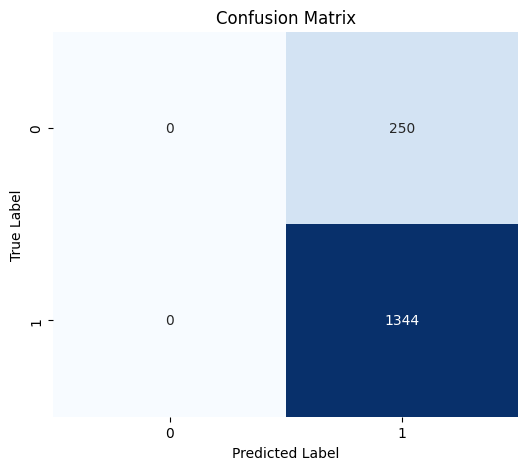

In [8]:
# load Bert model and change epoch to 5
model = BertForSequenceClassification.from_pretrained("bert-base-chinese", num_labels=2)

training_args = TrainingArguments(
    output_dir='./results',          # directory to save output
    evaluation_strategy="epoch",     # evaluate after each epoch
    save_strategy="epoch",           # save model after each epoch 
    per_device_train_batch_size=16,  # batch size per device for training
    per_device_eval_batch_size=16,   # batch size per device for evaluation
    num_train_epochs=5,              # number of training epochs
    logging_dir='./logs',            # directory to save logs
    logging_steps=10,                # frequency of logging steps
    load_best_model_at_end=True      # load the best model at the end of training
)

# use the Trainer API for model training and validation
trainer = Trainer(
    model=model,                         # model to be trained
    args=training_args,                  # training arguments
    train_dataset=train_dataset,         # training dataset
    eval_dataset=val_dataset             # validation dataset
)

# start training
trainer.train()

# evaluate model
results = trainer.evaluate()
print(f"Evaluation Results: {results}")

# compare real lables and predicted one
true_labels = val_labels  # real labels
predictions = trainer.predict(val_dataset).predictions.argmax(-1)

# compute model accuracy, precision, recall, f1
accuracy = accuracy_score(true_labels, predictions)
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predictions, average='binary')

print(f"accuracy: {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# visualize matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Metrics and Confusion Matrix Analysis (Epoch = 5)

Accuracy: 84.32%
The model maintains a strong accuracy, but this metric alone may not fully reflect its performance due to class imbalance.

Precision: 84.32%
Among the predicted positive samples, 84.32% are correct, showing decent precision for the positive class.

Recall: 100.00%
The model achieves perfect recall for the positive class, identifying all actual positive samples correctly.

F1 Score: 91.49%
The harmonic mean of precision and recall remains high, indicating a strong balance of these metrics for the positive class.

Confusion Matrix Analysis

True Positives (TP): 1344
The model correctly identifies all positive samples, achieving perfect recall.

False Negatives (FN): 0
No positive samples are missed, highlighting the model's exceptional sensitivity to the positive class.

True Negatives (TN): 0
The model fails to classify any negative samples correctly, indicating complete neglect of the negative class.

False Positives (FP): 250
All negative samples are misclassified as positive, showing an inability to handle negative sentiments.